# Blending, error analysis and the Kaggle submission

1. Blend linear and tree models using the out-of-fold predictions saved in Phases 5 to 7, and score every blend honestly.
2. Look at where the final model still fails (which houses, which neighborhoods, which kinds of sales).
3. Fit the final models on all training houses, predict the Kaggle test set and write the submission file.

Blending happens in log space (the models predict log price); only the final submission is converted back to dollars.

In [1]:
# Make src/ importable from notebooks/ and reload edited modules automatically
%load_ext autoreload
%autoreload 2
import sys, pathlib, json, re, warnings
from datetime import date
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import HuberRegressor, Ridge, RidgeCV
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.svm import SVR

from src.cv import (ROOT, RAW_DIR, FIGURES_DIR, RESULTS_PATH, OOF_PATH, SEED, CV,
                    evaluate_oof, fold_rmse, log_result, show_results)
from src.features import make_catboost_preprocessor, make_linear_preprocessor, make_tree_preprocessor
from src.models import CatBoostNativeCats

warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")

train = pd.read_csv(RAW_DIR / "train.csv")
test = pd.read_csv(RAW_DIR / "test.csv")
X, X_test = train.drop(columns=["Id", "SalePrice"]), test.drop(columns=["Id"])
y = np.log1p(train["SalePrice"])
keep = ~train["Id"].isin([524, 1299]).to_numpy()
y_np = y.to_numpy()

oof = pd.read_csv(OOF_PATH)
results = pd.read_csv(RESULTS_PATH)

def find_column(prefix):
    """The one saved out-of-fold column whose name starts with prefix."""
    hits = [c for c in oof.columns if c.startswith(prefix)]
    assert len(hits) == 1, f"{prefix!r} matched {hits}"
    return hits[0]

# The candidate models: their saved out-of-fold predictions and the settings found in earlier phases
cols = {
    "Ridge": find_column("Ridge (alpha=8.38) | train without"),
    "Huber": find_column("Huber"),
    "SVR": find_column("SVR"),
    "LightGBM": find_column("LightGBM (Optuna"),
    "XGBoost": find_column("XGBoost"),
    "CatBoost": find_column("CatBoost"),
}
P = oof[list(cols.values())].to_numpy()
names = list(cols)
for n, c in cols.items():
    s = fold_rmse(y_np, oof[c].to_numpy())
    print(f"{n:9s} {s.mean():.4f} ± {s.std():.4f}   <- {c}")

Ridge     0.1277 ± 0.0256   <- Ridge (alpha=8.38) | train without 524 & 1299
Huber     0.1261 ± 0.0229   <- Huber (alpha=30) | linear_full
SVR       0.1252 ± 0.0238   <- SVR (C=3, gamma=0.001) | linear_full, no 524/1299
LightGBM  0.1231 ± 0.0186   <- LightGBM (Optuna, 60 trials) | tree_features, no 524/1299
XGBoost   0.1220 ± 0.0194   <- XGBoost | tree_features, no 524/1299
CatBoost  0.1219 ± 0.0146   <- CatBoost | native categoricals, no 524/1299


The six candidates and their scores, all on the same folds and scored on all houses: three linear-type models (Ridge 0.1277, Huber 0.1261, SVR 0.1252) and three boosters (LightGBM 0.1231, XGBoost 0.1220, CatBoost 0.1219). Their out-of-fold predictions were saved in Phases 5 to 7, so blending them costs nothing: no model is retrained here.

In [2]:
# Every blend is scored the same way as single models: RMSE per shared fold, all houses
def score(pred):
    s = fold_rmse(y_np, pred)
    return s.mean(), s.std(), s

best_single = min(names, key=lambda n: score(oof[cols[n]].to_numpy())[0])
s_best_single = score(oof[cols[best_single]].to_numpy())[2]

def show(label, pred):
    m, sd, s = score(pred)
    better = int((s < s_best_single).sum())
    print(f"{label:40s} {m:.4f} ± {sd:.4f} | better than {best_single} on {better} of 5 folds")
    return s

def avg(*models):
    return P[:, [names.index(m) for m in models]].mean(axis=1)

blends = {
    "Ridge + LightGBM": avg("Ridge", "LightGBM"),
    "Ridge + CatBoost": avg("Ridge", "CatBoost"),
    "Huber + CatBoost": avg("Huber", "CatBoost"),
    "SVR + CatBoost": avg("SVR", "CatBoost"),
    "CatBoost + XGBoost + LightGBM": avg("CatBoost", "XGBoost", "LightGBM"),
    "Ridge + CatBoost + XGBoost": avg("Ridge", "CatBoost", "XGBoost"),
    "Ridge + SVR + CatBoost + XGBoost": avg("Ridge", "SVR", "CatBoost", "XGBoost"),
    "all 6 (equal weights)": P.mean(axis=1),
}
print(f"best single model: {best_single}\n")
blend_scores = {label: show(label, pred) for label, pred in blends.items()}

best single model: CatBoost

Ridge + LightGBM                         0.1212 ± 0.0221 | better than CatBoost on 4 of 5 folds
Ridge + CatBoost                         0.1209 ± 0.0197 | better than CatBoost on 4 of 5 folds
Huber + CatBoost                         0.1194 ± 0.0191 | better than CatBoost on 4 of 5 folds
SVR + CatBoost                           0.1203 ± 0.0194 | better than CatBoost on 4 of 5 folds
CatBoost + XGBoost + LightGBM            0.1207 ± 0.0176 | better than CatBoost on 4 of 5 folds
Ridge + CatBoost + XGBoost               0.1197 ± 0.0198 | better than CatBoost on 4 of 5 folds
Ridge + SVR + CatBoost + XGBoost         0.1196 ± 0.0211 | better than CatBoost on 4 of 5 folds
all 6 (equal weights)                    0.1193 ± 0.0213 | better than CatBoost on 4 of 5 folds


Every blend beats the best single model (CatBoost, 0.1219), each on 4 of 5 folds.

The best ones mix the two families:
- all 6 with equal weights: 0.1193
- Huber + CatBoost: 0.1194, with only two models
- Ridge + SVR + CatBoost + XGBoost: 0.1196

Huber + CatBoost (0.1194) does better than Ridge + CatBoost (0.1209). Both are a linear model plus a booster, but Huber's errors differ more from CatBoost's because it handles the outliers in its own way.

Averaging three boosters (0.1207) also helps, but less than adding a linear model, which matches the error correlations from Phase 6 (0.94 between boosters, about 0.85 between families).

In [3]:
# Optimized weights, done honestly: for each fold, the weights are learned on the other 4 folds only.
# (Weights are non-negative and add up to 1; the two outliers are left out when learning them.)
def optimize_weights(P_part, y_part):
    k = P_part.shape[1]
    loss = lambda w: np.sqrt(np.mean((y_part - P_part @ w) ** 2))
    res = minimize(loss, np.full(k, 1 / k), method="SLSQP", bounds=[(0, 1)] * k,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    return res.x

pred_w, fold_weights = np.empty(len(y_np)), []
for tr_idx, va_idx in CV.split(P):
    tr_idx = tr_idx[keep[tr_idx]]
    w = optimize_weights(P[tr_idx], y_np[tr_idx])
    pred_w[va_idx] = P[va_idx] @ w
    fold_weights.append(w)
fold_weights = pd.DataFrame(fold_weights, columns=names, index=[f"fold {k}" for k in range(1, 6)])
print("weights learned in each fold:\n", fold_weights.round(2), "\n")
blend_scores["optimized weights (honest)"] = show("optimized weights (honest)", pred_w)

# For comparison: weights learned on ALL the out-of-fold predictions and scored on the same ones
w_all = optimize_weights(P[keep], y_np[keep])
show("optimized weights (fitted and scored on same)", P @ w_all)
print("weights on all folds:", {n: round(float(w), 2) for n, w in zip(names, w_all)})

weights learned in each fold:
         Ridge  Huber   SVR  LightGBM  XGBoost  CatBoost
fold 1   0.00   0.30  0.31      0.06     0.20      0.13
fold 2   0.08   0.30  0.28      0.00     0.33      0.01
fold 3   0.05   0.31  0.17      0.00     0.48      0.00
fold 4   0.17   0.21  0.18      0.13     0.15      0.15
fold 5   0.24   0.20  0.18      0.00     0.25      0.13 

optimized weights (honest)               0.1202 ± 0.0218 | better than CatBoost on 4 of 5 folds
optimized weights (fitted and scored on same) 0.1195 ± 0.0223 | better than CatBoost on 4 of 5 folds
weights on all folds: {'Ridge': 0.08, 'Huber': 0.28, 'SVR': 0.23, 'LightGBM': 0.0, 'XGBoost': 0.33, 'CatBoost': 0.07}


Learning the weights doesn't pay off. The honest version (weights learned on 4 folds, applied to the 5th) scores 0.1202, worse than simply giving all six models equal weights (0.1193). Learning and scoring the weights on the same predictions looks better (0.1195), but that's the optimistic version.

The weights jump around between folds: XGBoost goes from 0.15 to 0.48, CatBoost from 0.00 to 0.15, LightGBM is often 0. The models are so similar that many different weightings fit the data almost equally well, so the optimizer picks up noise. Equal weights can't overfit, and with only about 1,450 houses that robustness is worth more than fine-tuned weights.

In [4]:
# Stacking with scikit-learn: a meta-model (RidgeCV) learns how to combine the base models,
# trained on out-of-fold predictions made inside each training fold. Two fast base models here.
tuned = json.loads(results.loc[results["model"].str.startswith("LightGBM (Optuna"), "params"].iloc[0])
LGBM_FIXED = {"subsample_freq": 1, "random_state": SEED, "verbose": -1}

stack = StackingRegressor(
    estimators=[("ridge", make_pipeline(make_linear_preprocessor(), Ridge(alpha=8.38))),
                ("lgbm", Pipeline([("prep", make_tree_preprocessor()), ("model", LGBMRegressor(**tuned, **LGBM_FIXED))]))],
    final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 13)),
    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
)
s_stack, p_stack = evaluate_oof(stack, X, y, "Stacking (Ridge + LightGBM, RidgeCV meta)", "no 524/1299",
                                train_keep=keep, phase=8, n_features=2, notes="meta-model on inner out-of-fold predictions")
blend_scores["stacking Ridge + LightGBM"] = s_stack
print(f"vs simple average Ridge + LightGBM: {blend_scores['Ridge + LightGBM'].mean():.4f}")

Stacking (Ridge + LightGBM, RidgeCV meta) [no 524/1299]: RMSE 0.1215 ± 0.0221 | folds [0.1249, 0.1055, 0.1629, 0.1117, 0.1024]
vs simple average Ridge + LightGBM: 0.1212


Stacking Ridge and LightGBM with a RidgeCV meta-model gets 0.1215, no better than simply averaging the same two models (0.1212). Same lesson as the weights: with two similar-quality models, a learned combination has nothing to gain over a plain average and adds complexity (and a whole extra layer of CV).

In [5]:
# Choosing the final blend: the best honest score, but prefer a simple average when it's within 0.0005
summary = pd.DataFrame({k: {"RMSE": v.mean(), "std": v.std()} for k, v in blend_scores.items()}).T.sort_values("RMSE")
print(summary.round(4).to_string())

best_label = summary.index[0]
simple = [k for k in summary.index if k in blends]
if best_label not in blends and summary.loc[simple[0], "RMSE"] - summary.loc[best_label, "RMSE"] < 0.0005:
    best_label = simple[0]
print(f"\nfinal blend: {best_label}")

# Components and weights of the final blend (used again for the test predictions).
# The CV score reported for it is always the honest one.
if best_label == "optimized weights (honest)":
    final_weights = {n: float(w) for n, w in zip(names, w_all) if w > 0.005}   # weights from all folds, for the test set
    final_weights = {n: w / sum(final_weights.values()) for n, w in final_weights.items()}
    final_oof = pred_w                                                         # honest out-of-fold blend
elif best_label in blends:
    members = names if best_label.startswith("all 6") else [n for n in names if re.search(rf"\b{n}\b", best_label)]
    final_weights = {n: 1 / len(members) for n in members}
    final_oof = blends[best_label]
else:
    final_weights = None                                                       # stacking: refitted as one model below
    final_oof = p_stack
print("weights:", {k: round(v, 3) for k, v in final_weights.items()} if final_weights else "stacking meta-model")

s_final = fold_rmse(y_np, final_oof)
log_result(f"Final blend: {best_label}", "blend of saved OOF predictions", final_weights or {}, s_final,
           phase=8, n_features=len(final_weights) if final_weights else 2,
           notes="honest CV score; models listed in params")
print(f"final blend CV RMSE: {s_final.mean():.4f} ± {s_final.std():.4f} | folds {s_final.round(4).tolist()}")

                                    RMSE     std
all 6 (equal weights)             0.1193  0.0213
Huber + CatBoost                  0.1194  0.0191
Ridge + SVR + CatBoost + XGBoost  0.1196  0.0211
Ridge + CatBoost + XGBoost        0.1197  0.0198
optimized weights (honest)        0.1202  0.0218
SVR + CatBoost                    0.1203  0.0194
CatBoost + XGBoost + LightGBM     0.1207  0.0176
Ridge + CatBoost                  0.1209  0.0197
Ridge + LightGBM                  0.1212  0.0221
stacking Ridge + LightGBM         0.1215  0.0221

final blend: all 6 (equal weights)
weights: {'Ridge': 0.167, 'Huber': 0.167, 'SVR': 0.167, 'LightGBM': 0.167, 'XGBoost': 0.167, 'CatBoost': 0.167}
final blend CV RMSE: 0.1193 ± 0.0213 | folds [0.1252, 0.1041, 0.1579, 0.1105, 0.0987]


The final model is the equal-weight average of all six (0.1193 ± 0.021). It's both the best honest score and a simple average, so the rule picks it directly.

Folds: 0.125, 0.104, 0.158, 0.111, 0.099. Fold 3 (the one with houses 524 and 1299) is still the worst, but every fold improved on the best single model.

If I wanted fewer models to maintain, Huber + CatBoost scores practically the same (0.1194) with just two.

In [6]:
# Error analysis 1: the 20 houses the final blend gets most wrong
err = train[["Id", "SalePrice", "Neighborhood", "SaleCondition", "OverallQual", "GrLivArea", "YearBuilt"]].copy()
err["predicted"] = np.expm1(final_oof).round(-2)
err["log_error"] = y_np - final_oof            # positive = sold for more than predicted
err["pct_off"] = (np.expm1(err["log_error"]) * 100).round(1)
print(err.reindex(err["log_error"].abs().sort_values(ascending=False).index).head(20).to_string(index=False))

  Id  SalePrice Neighborhood SaleCondition  OverallQual  GrLivArea  YearBuilt  predicted  log_error  pct_off
1299     160000      Edwards       Partial           10       5642       2008   754500.0  -1.550877    -78.8
 524     184750      Edwards       Partial           10       4676       2007   659300.0  -1.272247    -72.0
  31      40000       IDOTRR        Normal            4       1317       1920    94400.0  -0.858972    -57.6
 633      82500       NWAmes        Family            7       1411       1977   173500.0  -0.743379    -52.4
 496      34900       IDOTRR       Abnorml            4        720       1920    68700.0  -0.677518    -49.2
 463      62383       Sawyer        Normal            5        864       1965   122700.0  -0.676803    -49.2
1325     147000      Somerst       Partial            8       1795       2006   287700.0  -0.671649    -48.9
 917      35311       IDOTRR       Abnorml            2        480       1949    64000.0  -0.595150    -44.9
 969      37900    

The two worst are still 1299 and 524: predicted \$750k and \$660k, sold for \$160k and \$185k. No model trained on normal sales can predict those prices from the features.

Almost all of the top 20 are over-predictions (the house sold for less than expected), and almost all are unusual sales: Abnorml, Partial, Family, Alloca. Most of the rest are very old, cheap houses in IDOTRR, OldTown and Edwards (31, 496, 917, 969). Only four are under-predictions: 689, a new house in StoneBr sold as a Partial sale (\$392k vs \$243k predicted), and three abnormal sales (971, 682, 89).

In [7]:
# Error analysis 2: where are the errors concentrated?
def group_rmse(by):
    g = err.groupby(by, observed=True)["log_error"]
    return pd.DataFrame({"houses": g.size(), "RMSE": g.apply(lambda e: np.sqrt(np.mean(e ** 2))),
                         "mean error": g.mean()}).round(4)

print("By sale condition:\n", group_rmse("SaleCondition").sort_values("RMSE", ascending=False), "\n")

# Price bands by PREDICTED price (bands by actual price would build in regression to the mean)
err["predicted band"] = pd.qcut(err["predicted"], 5, labels=["cheapest 20%", "2", "3", "4", "priciest 20%"])
print("By predicted price band:\n", group_rmse("predicted band"), "\n")

nb_table = group_rmse("Neighborhood")
print("Neighborhoods with the largest errors (at least 10 houses):\n",
      nb_table[nb_table["houses"] >= 10].sort_values("RMSE", ascending=False).head(8))

By sale condition:
                houses    RMSE  mean error
SaleCondition                            
Alloca             12  0.2343     -0.0250
Partial           125  0.2226     -0.0128
Family             20  0.2131     -0.0208
Abnorml           101  0.2002     -0.0263
AdjLand             4  0.0900      0.0185
Normal           1198  0.0895     -0.0006 

By predicted price band:
                 houses    RMSE  mean error
predicted band                            
cheapest 20%       293  0.1551     -0.0150
2                  291  0.0882      0.0028
3                  292  0.0884     -0.0044
4                  292  0.0861     -0.0028
priciest 20%       292  0.1621      0.0002 

Neighborhoods with the largest errors (at least 10 houses):
               houses    RMSE  mean error
Neighborhood                            
IDOTRR            37  0.2549     -0.0709
Edwards          100  0.2366     -0.0413
ClearCr           28  0.1398      0.0201
OldTown          113  0.1391     -0.0163
StoneB

By sale condition the difference is huge: normal sales (1,198 houses) have an RMSE of 0.0895, while Alloca, Partial, Family and Abnorml sales are at 0.20 to 0.23, more than twice as bad. Those roughly 260 unusual sales (18% of the houses) produce about 55% of the total squared error. The two outliers alone account for about 19%. Even without 524 and 1299, Partial sales are still harder (about 0.133).

By predicted price: the middle 60% of houses have an RMSE of about 0.087. The cheapest 20% (0.155) and the most expensive 20% (0.162) are much harder. The top band includes 524 and 1299; without them it's about 0.112, still above the middle. The model is best for ordinary houses and worst at both ends.

By neighborhood: IDOTRR (0.255) and Edwards (0.237) are the worst, and both are over-predicted on average (by about 7% and 4%). StoneBr and Crawfor are under-predicted by about 5%. That's the same pattern the 17-feature OLS showed in Phase 4, so the location effect still isn't fully captured. The trees only get Neighborhood as an integer code, so target encoding Neighborhood would be the next thing to try.

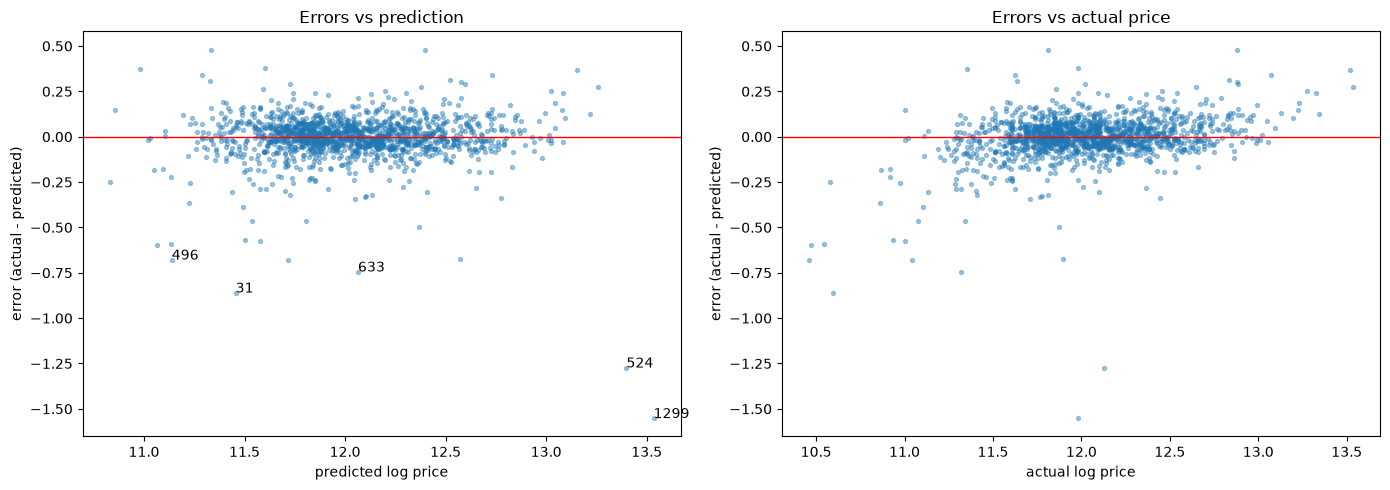

In [8]:
# Error analysis 3: residuals against predicted and actual price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(final_oof, err["log_error"], s=8, alpha=0.4)
axes[0].set(xlabel="predicted log price", ylabel="error (actual - predicted)", title="Errors vs prediction")
axes[1].scatter(y_np, err["log_error"], s=8, alpha=0.4)
axes[1].set(xlabel="actual log price", ylabel="error (actual - predicted)", title="Errors vs actual price")
for ax in axes:
    ax.axhline(0, color="red", lw=1)
for _, r in err.reindex(err["log_error"].abs().sort_values(ascending=False).index).head(5).iterrows():
    i = int(np.flatnonzero(train["Id"].to_numpy() == r["Id"])[0])
    axes[0].annotate(str(r["Id"]), (final_oof[i], r["log_error"]))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_final_errors.png", dpi=150, bbox_inches="tight")
plt.show()

Against the predicted price, the errors are centered on 0 with a fairly even spread from about 11.5 to 13, apart from the outliers labeled in the plot. That's what a well-calibrated model should look like.

Against the actual price, there's a clear tilt: cheap houses have negative errors and expensive ones positive. That's regression to the mean. A model predicts something close to the average for a given set of features, so the houses that actually sold at the extremes always look under- or over-predicted. That's why the price bands above were built on the predicted price, not the actual one.

In [9]:
# Final fit: every model in the blend is trained on ALL training houses, then predicts the test set
def final_model(name):
    if name == "Ridge":
        alpha = float(re.search(r"alpha=([\d.]+)", cols["Ridge"]).group(1))
        return make_pipeline(make_linear_preprocessor(), Ridge(alpha=alpha)), keep
    if name == "Huber":
        alpha = float(re.search(r"alpha=([\d.]+)", cols["Huber"]).group(1))
        return make_pipeline(make_linear_preprocessor(), HuberRegressor(epsilon=1.35, alpha=alpha, max_iter=5000)), np.ones(len(y), bool)
    if name == "SVR":
        C_, gamma = re.search(r"C=([\d.]+), gamma=([\w.]+)", cols["SVR"]).groups()
        gamma = gamma if gamma == "scale" else float(gamma)
        return make_pipeline(make_linear_preprocessor(), SVR(kernel="rbf", C=float(C_), gamma=gamma, epsilon=0.01)), keep
    if name == "LightGBM":
        return Pipeline([("prep", make_tree_preprocessor()), ("model", LGBMRegressor(**tuned, **LGBM_FIXED))]), keep
    if name == "XGBoost":
        return Pipeline([("prep", make_tree_preprocessor()), ("model", XGBRegressor(
            n_estimators=2000, learning_rate=0.01, max_depth=4, min_child_weight=1, subsample=0.7,
            colsample_bytree=0.5, reg_lambda=1.0, tree_method="hist", random_state=SEED))]), keep
    if name == "CatBoost":
        return Pipeline([("prep", make_catboost_preprocessor()),
                         ("model", CatBoostNativeCats(iterations=1500, learning_rate=0.03, depth=6,
                                                      l2_leaf_reg=3, random_seed=SEED))]), keep
    raise ValueError(name)

test_preds = {}
if final_weights:
    for name in final_weights:
        model, mask = final_model(name)
        test_preds[name] = model.fit(X[mask], y[mask]).predict(X_test)
        print(f"{name:9s} fitted on {int(mask.sum())} houses | test median ${np.expm1(np.median(test_preds[name])):,.0f}")
    test_log = sum(w * test_preds[n] for n, w in final_weights.items())
else:
    test_log = stack.fit(X[keep], y[keep]).predict(X_test)

# How much do the models agree on the test set?
if len(test_preds) > 1:
    print("\ncorrelation of test predictions:\n", pd.DataFrame(test_preds).corr().round(3))

Ridge     fitted on 1458 houses | test median $157,900
Huber     fitted on 1460 houses | test median $158,693
SVR       fitted on 1458 houses | test median $158,948
LightGBM  fitted on 1458 houses | test median $156,373
XGBoost   fitted on 1458 houses | test median $156,864
CatBoost  fitted on 1458 houses | test median $156,471

correlation of test predictions:
           Ridge  Huber    SVR  LightGBM  XGBoost  CatBoost
Ridge     1.000  0.997  0.994     0.987    0.988     0.989
Huber     0.997  1.000  0.994     0.985    0.985     0.987
SVR       0.994  0.994  1.000     0.991    0.989     0.991
LightGBM  0.987  0.985  0.991     1.000    0.997     0.996
XGBoost   0.988  0.985  0.989     0.997    1.000     0.996
CatBoost  0.989  0.987  0.991     0.996    0.996     1.000


Each of the six models is refitted on all the training houses (1,458 without 524 and 1299; Huber on all 1,460) and predicts the 1,459 test houses.

The models agree closely on the test set: test medians between \$156k and \$159k, and correlations of 0.985 to 0.997. The linear models agree most with each other, and so do the boosters, the same family split as in the training errors.

count      1459.0
mean     178406.0
std       77144.0
min       47024.0
25%      126606.0
50%      157147.0
75%      209297.0
max      707340.0

train median $163,000 | test predictions median $157,147


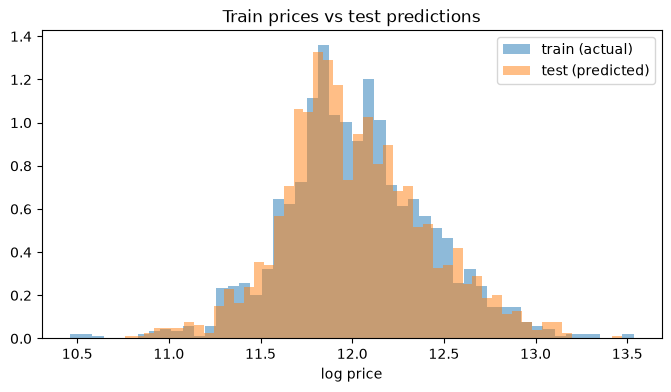

saved: submissions/submission_20261111_cv0.1193.csv


In [10]:
# The submission file, with sanity checks
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": np.expm1(test_log)})

assert len(submission) == 1459 or len(submission) == len(test), "one row per test house"
assert submission["SalePrice"].notna().all() and (submission["SalePrice"] > 0).all(), "no missing or negative prices"
assert submission["Id"].is_unique

print(submission["SalePrice"].describe().round(0).to_string())
print(f"\ntrain median ${train['SalePrice'].median():,.0f} | test predictions median ${submission['SalePrice'].median():,.0f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log1p(train["SalePrice"]), bins=50, alpha=0.5, density=True, label="train (actual)")
ax.hist(test_log, bins=50, alpha=0.5, density=True, label="test (predicted)")
ax.set(xlabel="log price", title="Train prices vs test predictions")
ax.legend()
fig.savefig(FIGURES_DIR / "08_test_vs_train.png", dpi=150, bbox_inches="tight")
plt.show()

out_dir = ROOT / "submissions"
out_dir.mkdir(exist_ok=True)
path = out_dir / f"submission_{date.today():%Y%m%d}_cv{s_final.mean():.4f}.csv"
submission.to_csv(path, index=False)
print("saved:", path.relative_to(ROOT))

1,459 rows, no missing or negative prices, unique Ids. Predictions range from \$47k to \$707k with a median of \$157k (the train median is \$163k).

The histogram of test predictions overlaps the training prices closely. The predictions are a little narrower at both tails, which is expected: a model predicts something close to the average for each kind of house, so its predictions spread less than real prices do.

Saved as submissions/submission_20261111_cv0.1193.csv.

In [11]:
# The final results table
print(show_results().head(20).to_string())

    phase                                        model                         feature_set  n_features  cv_rmse_mean  cv_rmse_std                                              notes
0       8           Final blend: all 6 (equal weights)      blend of saved OOF predictions           6       0.11928      0.02125           honest CV score; models listed in params
1       8    Stacking (Ridge + LightGBM, RidgeCV meta)                         no 524/1299           2       0.12150      0.02210        meta-model on inner out-of-fold predictions
2       6                                     CatBoost    native categoricals, no 524/1299          91       0.12191      0.01456            untuned; 31 categorical columns as text
3       6                                      XGBoost          tree_features, no 524/1299          91       0.12205      0.01938                                            untuned
4       7                 LightGBM (Optuna, 60 trials)          tree_features, no 524/1299     

The final blend (0.1193) is at the top, followed by stacking (0.1215) and the single boosters (0.122 to 0.125). From the mean-only baseline in Phase 3 (0.399) to the final blend, the error dropped by 70%.

## Where the project ended

Final model: the equal-weight average of Ridge, Huber, SVR, LightGBM, XGBoost and CatBoost, with a CV RMSE of 0.1193 ± 0.021 on log price (about 12% typical error).

How the score got there:

| Step | CV RMSE |
|---|---|
| Predict the mean | 0.399 |
| OverallQual + log(GrLivArea), plain linear regression | 0.1995 |
| All features, OLS | 0.1495 |
| Ridge / Lasso (regularization) | 0.1315 |
| Ridge, without 524 and 1299 in training | 0.1277 |
| Best single booster (CatBoost) | 0.1219 |
| Blend of linear and tree models | 0.1193 |

What mattered most: the log target, cleaning and feature engineering, regularization and handling the two outliers. Blending linear and tree models added a further consistent gain. Hyperparameter tuning added very little (about 0.001 honestly), and learned blend weights or stacking did no better than a plain average.

Where the model still fails: unusual sales (Partial, Abnorml, Family, Alloca) are 18% of the houses but about 55% of the squared error, and the cheapest and most expensive houses are harder than the middle. Next steps would be target encoding for Neighborhood, and either a sale-condition flag or a separate treatment for non-normal sales.

Kaggle public score: 0.12081, against a CV score of 0.1193 ± 0.021. The gap (0.0015) is far smaller than the spread between folds, so CV was a reliable estimate of performance on new houses. The small difference fits the slight optimism from choosing settings and the blend on the same folds, and the random variation of one test set. The test set also has its own unusual sales.
